##  Simple Transport between graphs using FGW

This notebook proposes to compute the assignment of labeled graphs using FGW

In [1]:
import numpy as np
import os,sys
sys.path.append(os.path.realpath('../lib'))
from graph_multimodalsentence import graph_colors,draw_rel,draw_transp,Graph,wl_labeling,find_thresh,sp_to_adjency
from ot_distances import Fused_Gromov_Wasserstein_distance,Wasserstein_distance
import copy
from data_loader import load_local_data,histog,build_noisy_circular_graph
import matplotlib.pyplot as plt
import networkx as nx
from sentence_transformers import SentenceTransformer
from FGW import fgw_barycenters

c:\Users\lucie\OneDrive\Documents\TrustCalibration\FGW\.venv3\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


First example is a transport between two simple graphs with four nodes

In [2]:
method='shortest_path_weight'
embedding = SentenceTransformer('sentence-transformers/bert-base-nli-mean-tokens')
print("add sentences")
g1=Graph()
g1.add_sentence("Hello {f: smile} how are you [excited] {g: Shaking Head No} and how is {t: Negation} it going {f: neutral} {g: Talking 2}",embedding)
g2=Graph()
g2.add_sentence("Hello {f: sad} how are you [excited] {f: smile} {g: Talking} and how is {t: Negation} it going  {g: Lengthy Head Nod}",embedding)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7929.19it/s]


add sentences
Shaking Head No
Talking 2
Talking
Lengthy Head Nod


0 -187
1 -170
2 -172
3 -163
4 -181
5 -128


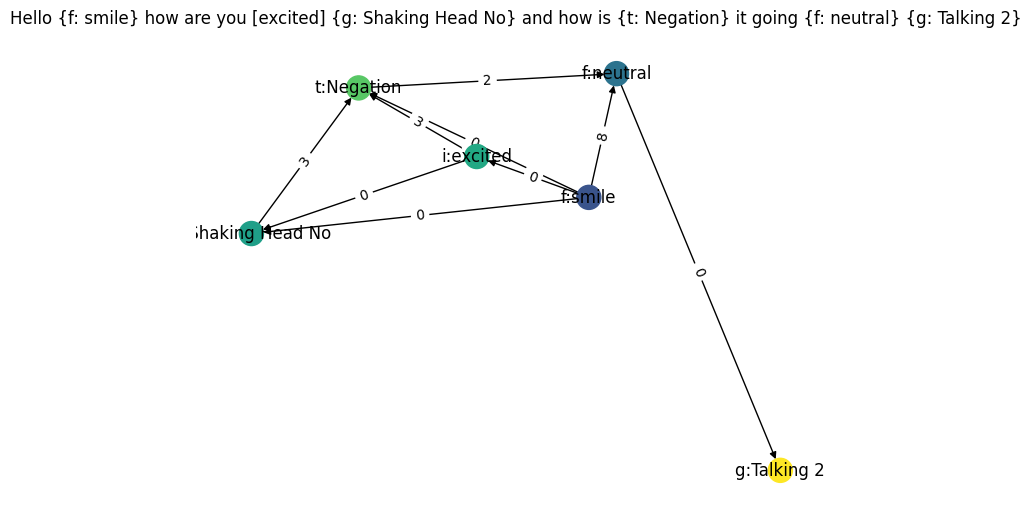

In [3]:
#plt.figure(figsize=(5,4))
vmin=0
vmax=7
draw_rel(g1.nx_graph,draw=False,vmin=-200,vmax=-150,with_labels=True)
#draw_rel(g2.nx_graph,draw=False,vmin=-5,vmax=5,with_labels=True,shiftx=5,swipy=True)
plt.title("Hello {f: smile} how are you [excited] {g: Shaking Head No} and how is {t: Negation} it going {f: neutral} {g: Talking 2}")
plt.show()

In [4]:
sample_text = "Hello {f: smile} how are you [excited] {g: Shaking Head No} and how is {t: Negation} it going {f: neutral} {g: Talking 2}"
gif_path = g1.create_sentence_gif(sample_text)
print(f"Animation successfully created at: {gif_path}")

0 -1
0 0
1 0
2 1
3 2
3 3
3 3
4 3
5 4
6 5
6 6
7 6
8 7
8 8
8 8
Animation successfully created at: gesture_animation.gif


In [5]:
alpha=0.5
dfgw=Fused_Gromov_Wasserstein_distance(alpha=alpha,features_metric='sqeuclidean',method=method).graph_d(g1,g2)
dw=Wasserstein_distance(features_metric='sqeuclidean').graph_d(g1,g2)
dgw=Fused_Gromov_Wasserstein_distance(alpha=1,features_metric='sqeuclidean',method=method).graph_d(g1,g2)
print('Wasserstein distance={}, Gromov distance={} \nFused Gromov-Wasserstein distance for alpha {} = {}'.format(dw,dgw,alpha,dfgw))

Wasserstein distance=0.24968469736408844, Gromov distance=0.14799596309192567 
Fused Gromov-Wasserstein distance for alpha 0.5 = 0.3336202225770607


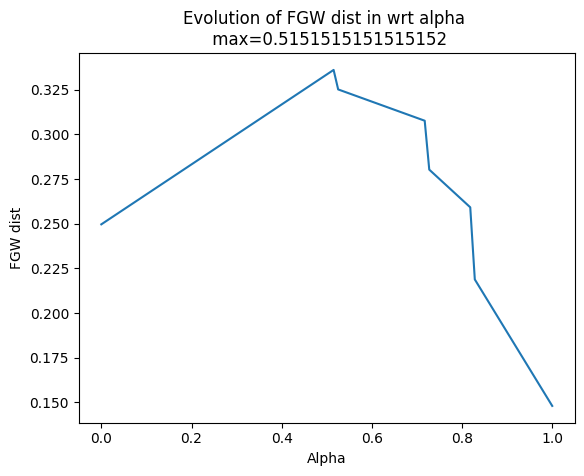

In [6]:
x=np.linspace(0,1,100)
j=0
alld=np.zeros(len(x))
for alpha in x:
    d=Fused_Gromov_Wasserstein_distance(alpha=alpha,features_metric='sqeuclidean',method=method).graph_d(g1,g2)
    alld[j]+=d
    j+=1
    
plt.plot(x,alld)
plt.title('Evolution of FGW dist in wrt alpha \n max={}'.format(x[np.argmax(alld)]))
plt.xlabel('Alpha')
plt.ylabel('FGW dist')
plt.show()

We see that neither Wasserstein distance on the label, or Gromov distance can discriminate between this two graphs, whereas FGW does not vanish.

We now build more complicated graphs with the following :

We plot the evolution of the FGW distance with respect to the alpha parameter

We see that the alpha which leads to best discriminate the graphs is between 0 and 1. We plot the coupling using this alpha :

0 -187
1 -170
2 -172
3 -163
4 -181
5 -128
0 -178
1 -170
2 -187
3 -146
4 -163
5 -173


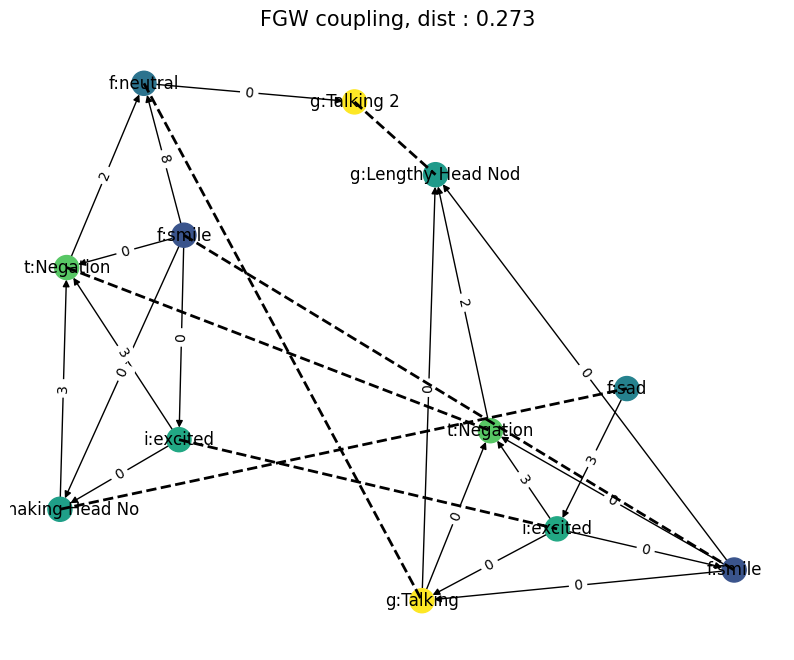

In [7]:
fig=plt.figure(figsize=(10,8))
thresh=0.004
gwdist=Fused_Gromov_Wasserstein_distance(alpha=0.14,features_metric='sqeuclidean',method=method)
d=gwdist.graph_d(g1,g2)
plt.title('FGW coupling, dist : '+str(np.round(d,3)),fontsize=15)
draw_transp(g1,g2,gwdist.transp,shiftx=2,shifty=0.5,thresh=thresh,
            swipy=True,swipx=False,with_labels=True,vmin=-200,vmax=-150)
plt.show()

We can also plot the GW coupling

0 -187
1 -170
2 -172
3 -163
4 -181
5 -128
0 -178
1 -170
2 -187
3 -146
4 -163
5 -173


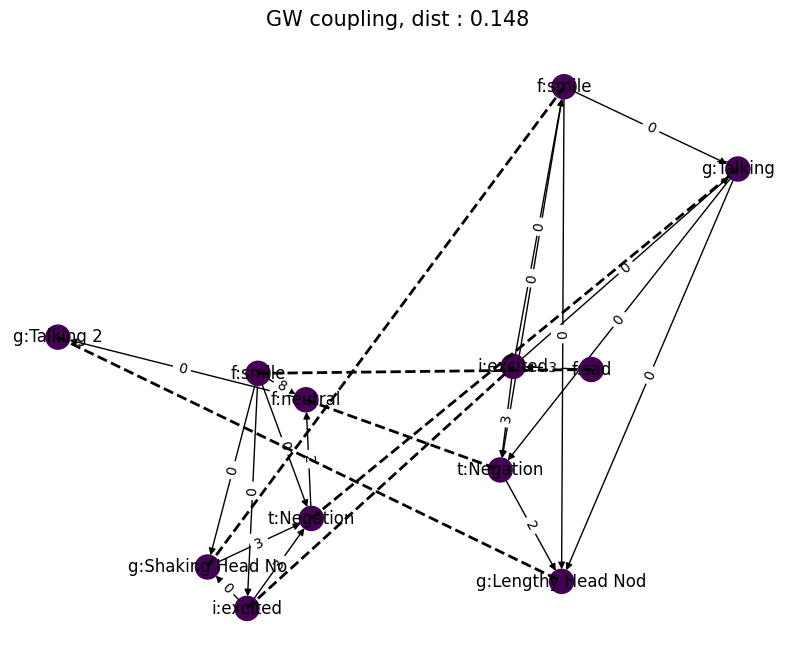

In [8]:
fig=plt.figure(figsize=(10,8))
thresh=0.004
gwdist=Fused_Gromov_Wasserstein_distance(alpha=1,features_metric='sqeuclidean',method=method)
d=gwdist.graph_d(g1,g2)
plt.title('GW coupling, dist : '+str(np.round(d,3)),fontsize=15)
draw_transp(g1,g2,gwdist.transp,shiftx=2,shifty=0.5,thresh=thresh,
            swipy=False,swipx=False,with_labels=True,vmin=vmin,vmax=11)

plt.show()

Processing dimension: ability
Processing dimension: benevolence
dimension    level_label
ability      High           10454
             Low            10332
             Medium         10390
benevolence  High            9879
             Low             9870
             Medium         10059
dtype: int64
Dimension ability: 31176 graphs available for alpha selection
dimension=ability, seed=49
Shrugging
shrugs
Gesture not found for value: shrugs
Gesture not found for value: shrugs
Looking Around
Shrugging
Agreeing 2
Pointing Forward
Shrugging
shrugging
Looking Around
Shaking Head No
Arm Gesture (Right)
Looking Around
Arm Gesture (Left)
Looking Around
Shrugging
Acknowledging
Acknowledging
Looking Around
Shrugging
Agreeing 2
Pointing (Right)
Nervously Look Around
Looking Around
Shrugging
Looking Around
Arm Gesture (Right)
Pointing
Looking Around
Shrugging
Talking 3
Look Around
Shaking Head No
Arm Gesture (Left)
Shaking Head No
Arm Gesture (Left)
nervously look around
Looking Around
Pointin

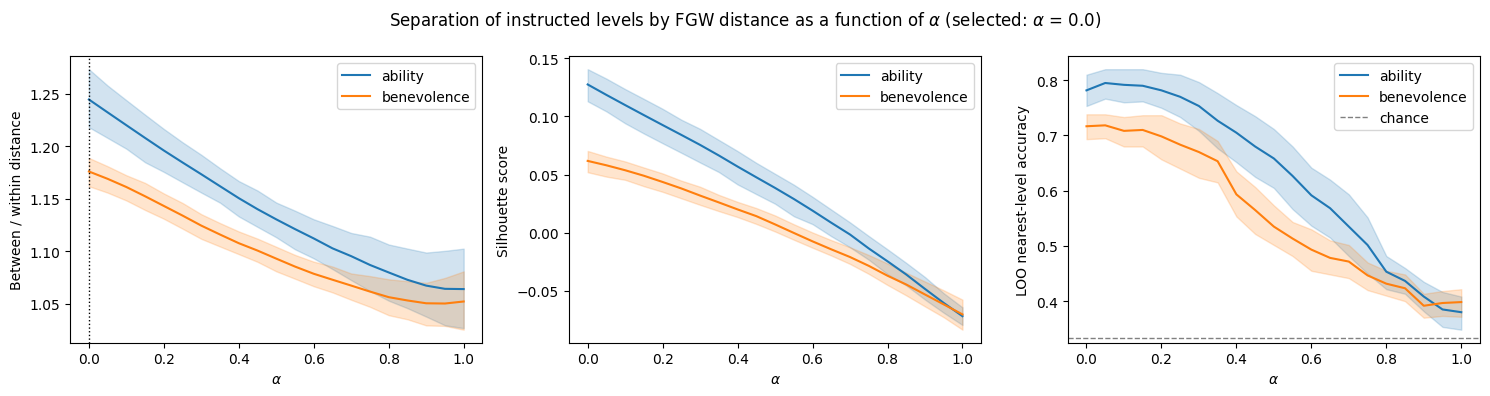

In [10]:
"""
Choice of the FGW trade-off parameter alpha by class separation.

For each alpha, we measure how well the FGW distance separates the instructed
levels (Low / Medium / High), separately for ability and benevolence:

  1. separation ratio  = mean between-level distance / mean within-level distance
  2. silhouette score  (sklearn, on the precomputed distance matrix)
  3. leave-one-out accuracy of a "nearest level" rule: each graph is assigned to
     the level whose other graphs are closest on average (cheap proxy for the
     nearest-barycenter classification, no barycenter needed)

All three use the INSTRUCTED level only, never the perceived level, so the choice
of alpha does not use the data later evaluated in H2.

Expects, as in your notebook: Graph, Fused_Gromov_Wasserstein_distance,
`embedding` and `method` already defined/imported.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score

# ---------------------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------------------
EXPLANATIONS = {"full_ability": "ability", "full_benevolence": "benevolence"}
GENDERS = ["neutral", "man", "woman"]
MODELS = ["gemma", "gpt", "mistral"]
TASKS = ["", "_QA"]
LEVELS = ["Low", "Medium", "High"]

SEEDS = [49, 65, 78, 91, 102, 115, 128, 141, 154, 167]   # 10 seeds; add more if time allows
N_PER_LEVEL = 20                       # graphs per level and seed -> 60 graphs, 1770 pairs
ALPHAS = np.round(np.linspace(0, 1, 21), 2)   # coarse grid; refine around the optimum afterwards
CRITERION = "ratio"                    # "ratio", "silhouette" or "accuracy": used to pick alpha

# Utterances used as study stimuli: exclude them so that alpha is chosen on
# data independent from the perceptual study (fill with their ids if available).
STUDY_IDS = set()

# ---------------------------------------------------------------------------
# Data loading (keeps track of the dimension, gender, model and task)
# ---------------------------------------------------------------------------
frames = []
for e, dim in EXPLANATIONS.items():    
    print(f"Processing dimension: {dim}")
    # the "controle" files are not needed here
    for g in GENDERS:
        for m in MODELS:
            for t in TASKS:
                path = ("../data_with_text_tag/generated_instructions_with_intention_"
                        f"explanation_{e}_gender_{g}_{m}{t}.csv")
                try:
                    d = pd.read_csv(path)
                except FileNotFoundError:
                    print(f"File not found: {path}")
                    continue
                d["dimension"] = dim
                d["gender"] = g
                d["model"] = m
                d["task"] = "QA" if t else "navigation"
                d["level_label"] = d[dim].astype(str).str.split(" ").str[0]
                frames.append(d)

df = pd.concat(frames, ignore_index=True)
df = df[df["level_label"].isin(LEVELS)]
if STUDY_IDS:
    df = df[~df.index.isin(STUDY_IDS)]
print(df.groupby(["dimension", "level_label"]).size())


# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
def build_graph(sentence):
    g = Graph()
    g.add_sentence(sentence, embedding)
    return g


def pairwise_distances(graphs, alphas):
    """FGW distance matrices for all alphas: shape (len(alphas), n, n).
    Each pair of graphs is built once and compared for every alpha.
    Failed computations are stored as NaN (not 0) and reported."""
    n = len(graphs)
    D = np.full((len(alphas), n, n), np.nan)
    for a in range(len(alphas)):
        np.fill_diagonal(D[a], 0.0)
    n_fail = 0
    for i in range(n):
        for j in range(i + 1, n):
            for a, alpha in enumerate(alphas):
                try:
                    d = Fused_Gromov_Wasserstein_distance(
                        alpha=alpha, features_metric="sqeuclidean", method=method
                    ).graph_d(graphs[i], graphs[j])
                except Exception:
                    d = np.nan
                    n_fail += 1
                D[a, i, j] = D[a, j, i] = d
    if n_fail:
        print(f"  {n_fail} failed FGW computations (stored as NaN)")
    return D


def separation_scores(D, labels):
    """Separation ratio, silhouette and leave-one-out nearest-level accuracy."""
    labels = np.asarray(labels)
    same = labels[:, None] == labels[None, :]
    off_diag = ~np.eye(len(labels), dtype=bool)
    valid = ~np.isnan(D)

    within = D[same & off_diag & valid].mean()
    between = D[~same & valid].mean()
    ratio = between / within if within > 0 else np.nan

    # silhouette needs a complete matrix: drop graphs with failed distances
    keep = valid.all(axis=1)
    if keep.sum() > len(LEVELS) and len(np.unique(labels[keep])) == len(LEVELS):
        sil = silhouette_score(D[np.ix_(keep, keep)], labels[keep], metric="precomputed")
    else:
        sil = np.nan

    # leave-one-out: mean distance from graph i to the other graphs of each level
    correct = []
    for i in range(len(labels)):
        mean_d = {}
        for lev in LEVELS:
            mask = (labels == lev) & off_diag[i] & valid[i]
            if mask.any():
                mean_d[lev] = D[i, mask].mean()
        if mean_d:
            correct.append(min(mean_d, key=mean_d.get) == labels[i])
    acc = np.mean(correct) if correct else np.nan

    return ratio, sil, acc


# ---------------------------------------------------------------------------
# Main loop: one stratified sample per seed and dimension
# ---------------------------------------------------------------------------
records = []
for dim in EXPLANATIONS.values():
    pool = df[df["dimension"] == dim]
    print(f"Dimension {dim}: {len(pool)} graphs available for alpha selection")
    for s in SEEDS:
        print(f"dimension={dim}, seed={s}")
        sample = pd.concat([pool[pool["level_label"] == lev].sample(N_PER_LEVEL, random_state=s)
                            for lev in LEVELS])
        graphs = [build_graph(txt) for txt in sample["instruction_with_intention"]]
        labels = sample["level_label"].to_numpy()

        D_all = pairwise_distances(graphs, ALPHAS)
        np.save(f"fgw_distances_{dim}_seed{s}.npy", D_all)   # avoid recomputing later

        for a, alpha in enumerate(ALPHAS):
            ratio, sil, acc = separation_scores(D_all[a], labels)
            records.append({"dimension": dim, "seed": s, "alpha": alpha,
                            "ratio": ratio, "silhouette": sil, "accuracy": acc})

res = pd.DataFrame(records)
res.to_csv("alpha_selection_results.csv", index=False)

# ---------------------------------------------------------------------------
# Choice of alpha and plots
# ---------------------------------------------------------------------------
summary = res.groupby(["dimension", "alpha"])[["ratio", "silhouette", "accuracy"]].mean()
best = {}
for dim in EXPLANATIONS.values():
    s_dim = summary.loc[dim]
    best[dim] = s_dim[CRITERION].idxmax()
    print(f"{dim}: best alpha by {CRITERION} = {best[dim]} "
          f"(ratio={s_dim.loc[best[dim], 'ratio']:.3f}, "
          f"silhouette={s_dim.loc[best[dim], 'silhouette']:.3f}, "
          f"accuracy={s_dim.loc[best[dim], 'accuracy']:.3f})")

# Single alpha for both dimensions: maximize the criterion averaged over dimensions
overall = res.groupby("alpha")[CRITERION].mean()
print(f"Overall best alpha by {CRITERION}: {overall.idxmax()}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, crit, ylab in zip(axes,
                          ["ratio", "silhouette", "accuracy"],
                          ["Between / within distance", "Silhouette score", "LOO nearest-level accuracy"]):
    sns.lineplot(data=res, x="alpha", y=crit, hue="dimension", errorbar=("ci", 95), ax=ax)
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(ylab)
    if crit == "accuracy":
        ax.axhline(1 / len(LEVELS), ls="--", c="grey", lw=1, label="chance")
    if crit == CRITERION:
        ax.axvline(overall.idxmax(), ls=":", c="k", lw=1)
    ax.legend()
fig.suptitle(rf"Separation of instructed levels by FGW distance as a function of $\alpha$ "
             rf"(selected: $\alpha$ = {overall.idxmax()})")
fig.tight_layout()
fig.savefig("tunealpha.png", dpi=300)
plt.show()

In [ ]:
def create_graph_from_data(x,embedding):
    graphs=Graph()
    graphs.add_sentence(x,embedding)
    return graphs

In [ ]:
import pandas as pd
data = pd.read_csv('../data_with_text_tag\generated_instructions_with_intention_explanation_full_ability_gender_neutral_gpt.csv')

data_high = data[data['ability']=='High']
data_low = data[data['ability']=='Low']
data_medium = data[data['ability']=='Medium']
graphs_high=[create_graph_from_data(x,embedding) for x in data_high.instruction_with_intention]
graphs_low=[create_graph_from_data(x,embedding) for x in data_low.instruction_with_intention]
graphs_medium=[create_graph_from_data(x,embedding) for x in data_medium.instruction_with_intention]

Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Hard Head Nod
Arm Gesture (Left)
Arm Gesture (Left)
Hard Head Nod
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Acknowledging
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture (Left)
Head Nod Yes
Arm Gesture 

In [ ]:
from graph_multimodalsentence import compute_barycenter

def createbary(graphs):
    # FGW barycenter with N = median number of nodes of the graphs
    return compute_barycenter(graphs, alpha=0.14)

In [ ]:
def from_numpy_array(G, adj_matrix, source_node_offset=0):
        """
        Populates the graph from a numpy adjacency matrix.
        
        Args:
            adj_matrix (np.ndarray): Square matrix where adj_matrix[i, j] is the weight.
            source_node_offset (int): The starting ID for nodes. 
                                      Useful if you are adding this matrix to an existing graph.
        """
        import numpy as np
        
        rows, cols = adj_matrix.shape
        if rows != cols:
            raise ValueError("Adjacency matrix must be square.")

        # 1. Ensure all nodes exist in the graph first
        for i in range(rows):
            node_id = i + source_node_offset
            if not G.nx_graph.has_node(node_id):
                G.nx_graph.add_node(node_id)
        
        # 2. Iterate through the matrix to add edges
        # We use np.nonzero to avoid iterating over thousands of zeros in sparse matrices
        nonzero_indices = np.nonzero(adj_matrix)
        
        for i, j in zip(*nonzero_indices):
            weight = adj_matrix[i, j]
            u = i + source_node_offset
            v = j + source_node_offset
            
            # Add edge with the weight from the matrix
            # You can add additional default attributes here (e.g., type='matrix_imported')
            G.nx_graph.add_edge(u, v, weight=weight)
            
        # 3. Update the internal node counter to prevent ID collisions in future additions
        G.n_nodes = max(G.n_nodes, rows + source_node_offset)
        
        print(f"Successfully imported {len(nonzero_indices[0])} edges from matrix.")


In [ ]:
bary_high=createbary(graphs_high)
bary_medium=createbary(graphs_medium)
bary_low=createbary(graphs_low)

Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.


0 -173
1 -164
2 -150
3 -201
4 -175
5 -166
6 -171
7 -169
8 -176
9 -191
10 -190
11 -153
12 -170
13 -154
14 -170


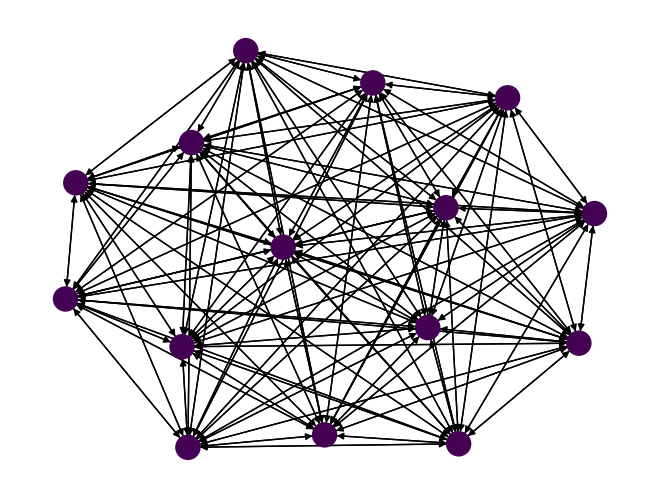

In [ ]:
draw_rel(bary_high .nx_graph,draw=False,vmin=-5,vmax=5,with_labels=True)

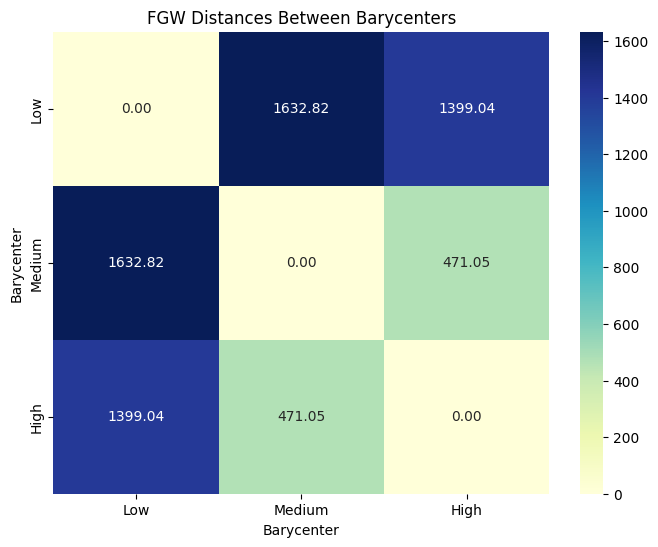

In [ ]:
gwdist=Fused_Gromov_Wasserstein_distance(alpha=0.14,features_metric='sqeuclidean',method=method)
d_low_high=gwdist.graph_d(bary_low,bary_high)*10000
d_low_medium=gwdist.graph_d(bary_low,bary_medium)*10000
d_medium_high=gwdist.graph_d(bary_medium,bary_high)*10000

#plot confusion matrix of distances between barycenters
import seaborn as sns
import matplotlib.pyplot as plt
distances = np.array([[0, d_low_medium, d_low_high],
                        [d_low_medium, 0, d_medium_high],
                        [d_low_high, d_medium_high, 0]])
plt.figure(figsize=(8, 6))
sns.heatmap(distances, annot=True, fmt=".2f", cmap="YlGnBu", xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
plt.title('FGW Distances Between Barycenters')
plt.xlabel('Barycenter')
plt.ylabel('Barycenter')
plt.show()

In [ ]:
# bootstrap confidence intervals for the distances

def bootstrap_confidence_interval(graphs1, graphs2, alpha=0.14, n_bootstrap=10):
    gwdist = Fused_Gromov_Wasserstein_distance(alpha=alpha, features_metric='sqeuclidean', method=method)
    distances = []
    
    for _ in range(n_bootstrap):
        # Sample with replacement from both graph sets
        sample1 = np.random.choice(graphs1, size=len(graphs1), replace=True)
        sample2 = np.random.choice(graphs2, size=len(graphs2), replace=True)
        
        # Create barycenters for the sampled graphs
        bary1 = createbary(sample1)
        bary2 = createbary(sample2)
        
        # Compute the distance between the two barycenters
        distance = gwdist.graph_d(bary1, bary2) * 10000
        distances.append(distance)
    
    # Calculate confidence intervals
    lower_bound = np.percentile(distances, 2.5)
    upper_bound = np.percentile(distances, 97.5)
    bootstraped_distance = np.mean(distances)
    
    return lower_bound, upper_bound, bootstraped_distance

In [ ]:
d_low_medium_ci = bootstrap_confidence_interval(graphs_low, graphs_medium)
d_low_high_ci = bootstrap_confidence_interval(graphs_low, graphs_high)
d_medium_high_ci = bootstrap_confidence_interval(graphs_medium, graphs_high)
print("Low -> Medium", d_low_medium_ci)
print("Low -> High", d_low_high_ci)
print("Medium -> High", d_medium_high_ci)

Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successfully imported 210 edges from matrix.
Successful